# **Load Dataset**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
file_path = "/content/drive/MyDrive/Fifa 23 Players Data.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (18539, 89)


,Known As,Full Name,Overall,Potential,Value(in Euro),Positions Played,Best Position,Nationality,Image Link,Age,...,LM Rating,CM Rating,RM Rating,LWB Rating,CDM Rating,RWB Rating,LB Rating,CB Rating,RB Rating,GK Rating
0,L. Messi,Lionel Messi,91,91,54000000,RW,CAM,Argentina,https://cdn.sofifa.net/players/158/023/23_60.png,35,...,91,88,91,67,66,67,62,53,62,22
1,K. Benzema,Karim Benzema,91,91,64000000,"CF,ST",CF,France,https://cdn.sofifa.net/players/165/153/23_60.png,34,...,89,84,89,67,67,67,63,58,63,21
2,R. Lewandowski,Robert Lewandowski,91,91,84000000,ST,ST,Poland,https://cdn.sofifa.net/players/188/545/23_60.png,33,...,86,83,86,67,69,67,64,63,64,22
3,K. De Bruyne,Kevin De Bruyne,91,91,107500000,"CM,CAM",CM,Belgium,https://cdn.sofifa.net/players/192/985/23_60.png,31,...,91,91,91,82,82,82,78,72,78,24
4,K. Mbappé,Kylian Mbappé,91,95,190500000,"ST,LW",ST,France,https://cdn.sofifa.net/players/231/747/23_60.png,23,...,92,84,92,70,66,70,66,57,66,21


In [4]:
# Check column names
print(df.columns)

# Dataset info
df.info()

# Check missing values
df.isnull().sum().sort_values(ascending=False)

Index(['Known As', 'Full Name', 'Overall', 'Potential', 'Value(in Euro)',
       'Positions Played', 'Best Position', 'Nationality', 'Image Link', 'Age',
       'Height(in cm)', 'Weight(in kg)', 'TotalStats', 'BaseStats',
       'Club Name', 'Wage(in Euro)', 'Release Clause', 'Club Position',
       'Contract Until', 'Club Jersey Number', 'Joined On', 'On Loan',
       'Preferred Foot', 'Weak Foot Rating', 'Skill Moves',
       'International Reputation', 'National Team Name',
       'National Team Image Link', 'National Team Position',
       'National Team Jersey Number', 'Attacking Work Rate',
       'Defensive Work Rate', 'Pace Total', 'Shooting Total', 'Passing Total',
       'Dribbling Total', 'Defending Total', 'Physicality Total', 'Crossing',
       'Finishing', 'Heading Accuracy', 'Short Passing', 'Volleys',
       'Dribbling', 'Curve', 'Freekick Accuracy', 'LongPassing', 'BallControl',
       'Acceleration', 'Sprint Speed', 'Agility', 'Reactions', 'Balance',
       'Shot Powe

,0
Known As,0
Full Name,0
Overall,0
Potential,0
Value(in Euro),0
...,...
RWB Rating,0
LB Rating,0
CB Rating,0
RB Rating,0


# **EDA**

In [5]:
plt.rcParams.update({'figure.dpi': 150, 'font.size': 11})
sns.set_style("whitegrid")

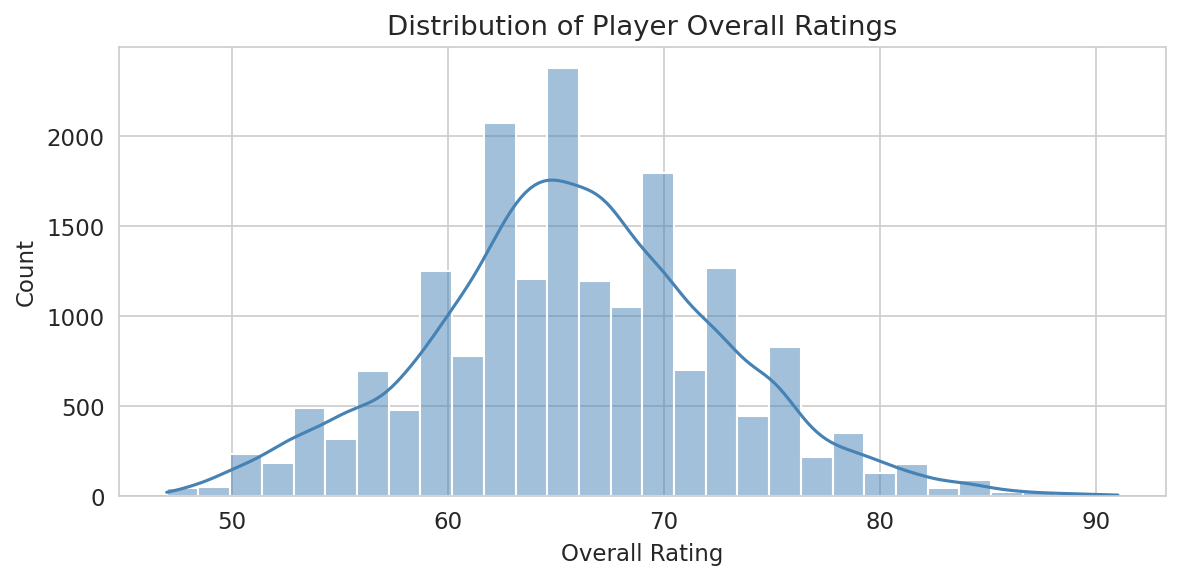

In [6]:
# Overall Rating Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Overall'], bins=30, kde=True, color='steelblue')
plt.title('Distribution of Player Overall Ratings')
plt.xlabel('Overall Rating')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('1_overall_distribution.png', bbox_inches='tight')
plt.show()

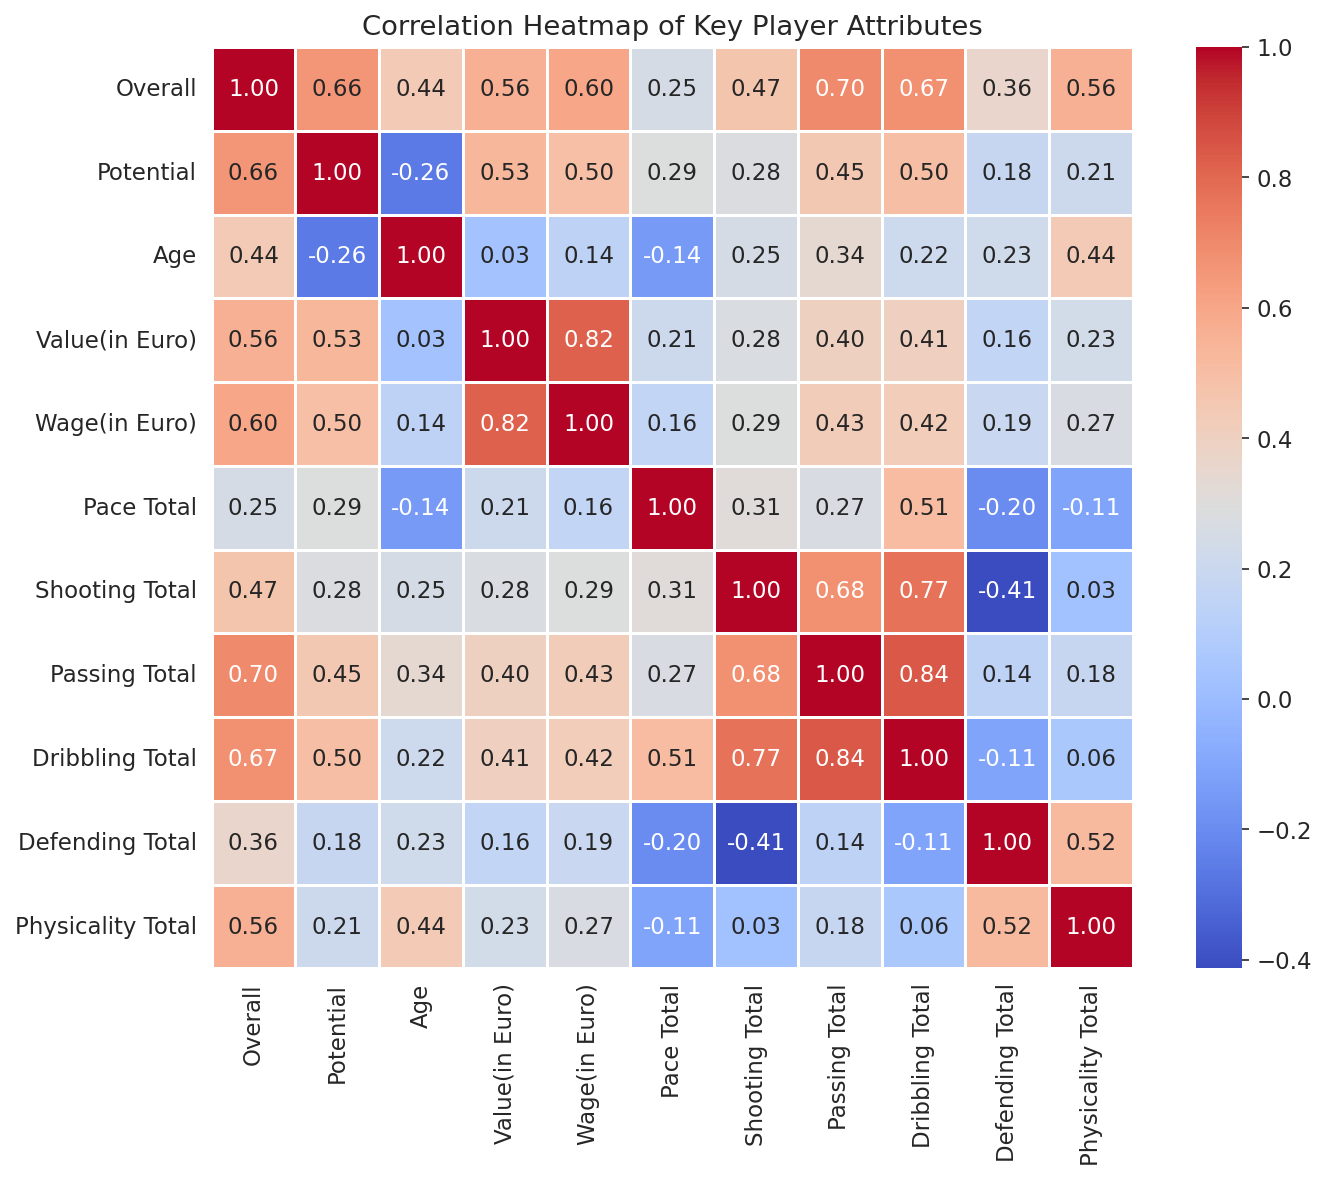

In [7]:
#Correlation Heatmap
key_cols = ['Overall', 'Potential', 'Age', 'Value(in Euro)', 'Wage(in Euro)',
            'Pace Total', 'Shooting Total', 'Passing Total',
            'Dribbling Total', 'Defending Total', 'Physicality Total']

plt.figure(figsize=(10, 8))
sns.heatmap(df[key_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Heatmap of Key Player Attributes')
plt.tight_layout()
plt.savefig('2_correlation_heatmap.png', bbox_inches='tight')
plt.show()

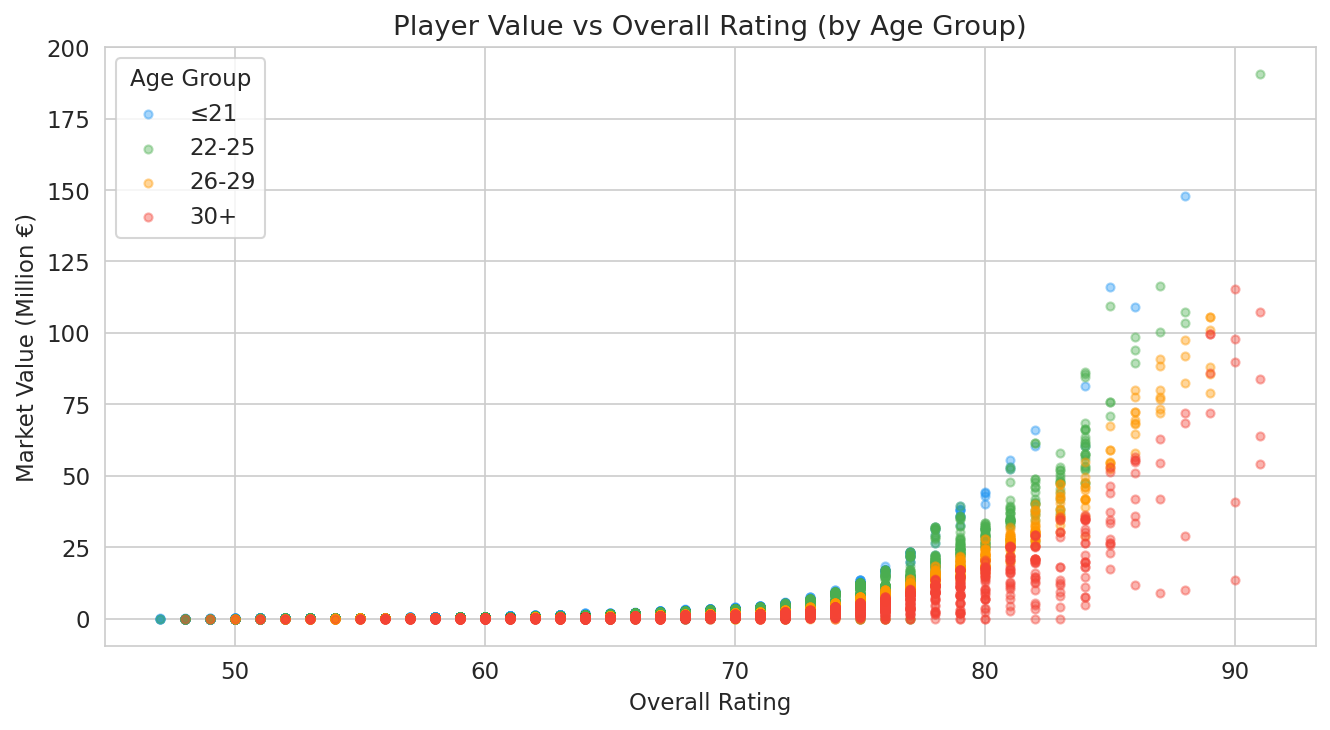

In [8]:
#Market Value vs Overall Rating
df['Age Group'] = pd.cut(df['Age'], bins=[15, 21, 25, 29, 40],
                          labels=['≤21', '22-25', '26-29', '30+'])

plt.figure(figsize=(9, 5))
for group, color in zip(['≤21','22-25','26-29','30+'],
                         ['#2196F3','#4CAF50','#FF9800','#F44336']):
    sub = df[df['Age Group'] == group]
    plt.scatter(sub['Overall'], sub['Value(in Euro)'] / 1e6,
                alpha=0.4, s=15, label=group, color=color)

plt.title('Player Value vs Overall Rating (by Age Group)')
plt.xlabel('Overall Rating')
plt.ylabel('Market Value (Million €)')
plt.legend(title='Age Group')
plt.tight_layout()
plt.savefig('3_value_vs_overall.png', bbox_inches='tight')
plt.show()

/tmp/ipykernel_4110/3414688966.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Skill Moves', palette='viridis', ax=axes[1])


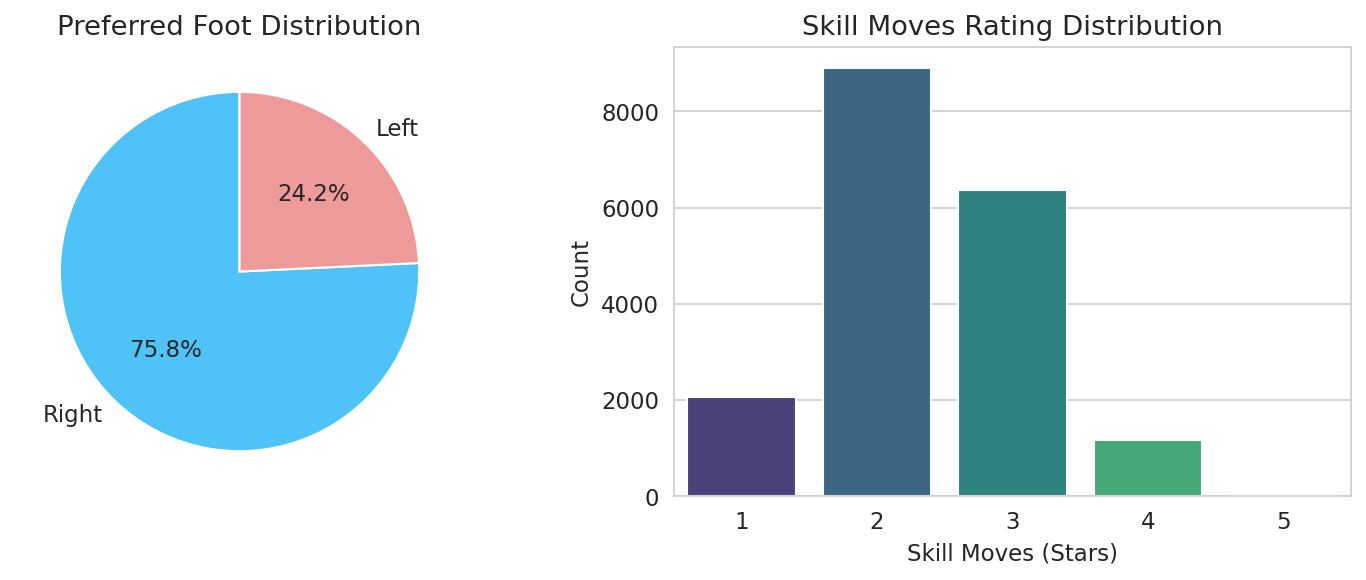

In [9]:
#Preferred Foot & Skill Moves Distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Preferred Foot
foot_counts = df['Preferred Foot'].value_counts()
axes[0].pie(foot_counts, labels=foot_counts.index, autopct='%1.1f%%',
            colors=['#4FC3F7', '#EF9A9A'], startangle=90)
axes[0].set_title('Preferred Foot Distribution')

# Skill Moves
sns.countplot(data=df, x='Skill Moves', palette='viridis', ax=axes[1])
axes[1].set_title('Skill Moves Rating Distribution')
axes[1].set_xlabel('Skill Moves (Stars)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('5_foot_and_skills.png', bbox_inches='tight')
plt.show()

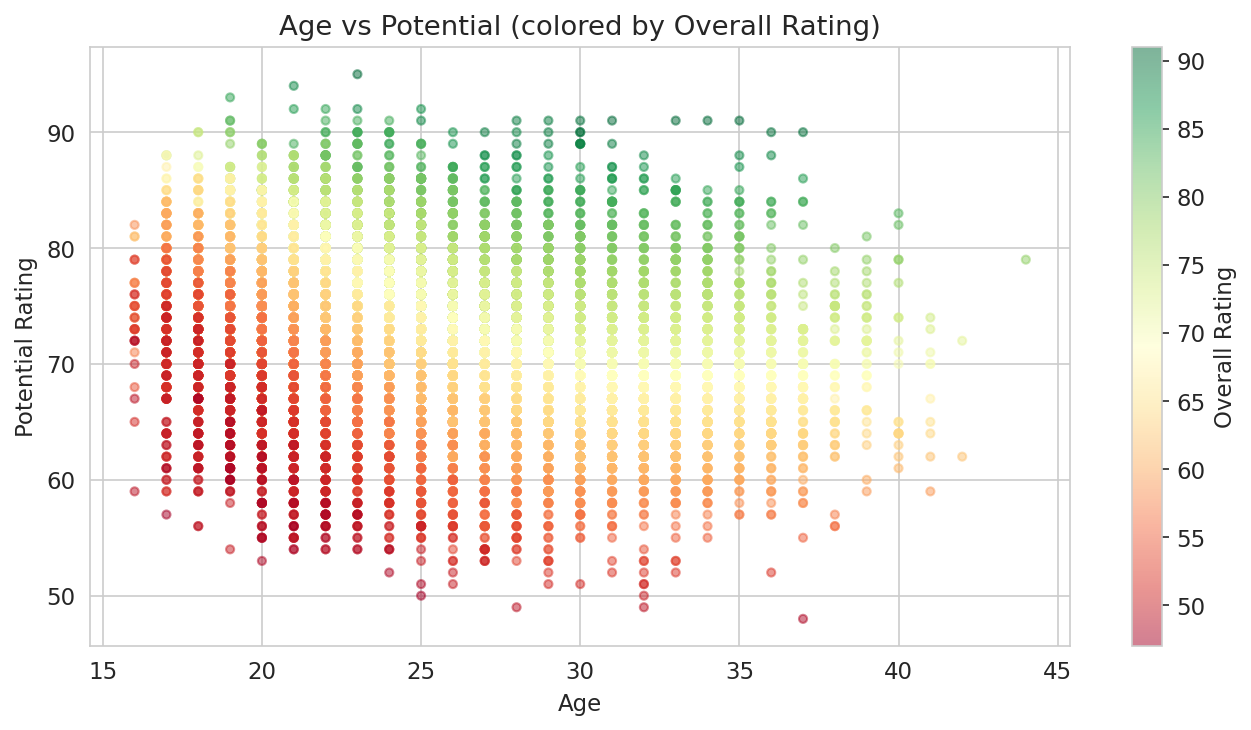

In [10]:
#Age vs Potential
plt.figure(figsize=(9, 5))
sc = plt.scatter(df['Age'], df['Potential'],
                 c=df['Overall'], cmap='RdYlGn',
                 alpha=0.5, s=15)
plt.colorbar(sc, label='Overall Rating')
plt.title('Age vs Potential (colored by Overall Rating)')
plt.xlabel('Age')
plt.ylabel('Potential Rating')
plt.tight_layout()
plt.savefig('6_age_vs_potential.png', bbox_inches='tight')
plt.show()

# **Dataset Pre-processing**

In [11]:
# Remove duplicates
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (18420, 90)


In [12]:
drop_columns = [
    'Known As',
    'Full Name',
    'Image Link',
    'National Team Image Link'
]

df = df.drop(columns=drop_columns, errors='ignore')

print("Shape after dropping columns:", df.shape)

Shape after dropping columns: (18420, 86)


In [13]:
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")

print(df.columns)

Index(['Overall', 'Potential', 'Value(in_Euro)', 'Positions_Played',
       'Best_Position', 'Nationality', 'Age', 'Height(in_cm)', 'Weight(in_kg)',
       'TotalStats', 'BaseStats', 'Club_Name', 'Wage(in_Euro)',
       'Release_Clause', 'Club_Position', 'Contract_Until',
       'Club_Jersey_Number', 'Joined_On', 'On_Loan', 'Preferred_Foot',
       'Weak_Foot_Rating', 'Skill_Moves', 'International_Reputation',
       'National_Team_Name', 'National_Team_Position',
       'National_Team_Jersey_Number', 'Attacking_Work_Rate',
       'Defensive_Work_Rate', 'Pace_Total', 'Shooting_Total', 'Passing_Total',
       'Dribbling_Total', 'Defending_Total', 'Physicality_Total', 'Crossing',
       'Finishing', 'Heading_Accuracy', 'Short_Passing', 'Volleys',
       'Dribbling', 'Curve', 'Freekick_Accuracy', 'LongPassing', 'BallControl',
       'Acceleration', 'Sprint_Speed', 'Agility', 'Reactions', 'Balance',
       'Shot_Power', 'Jumping', 'Stamina', 'Strength', 'Long_Shots',
       'Aggression', '

In [14]:
# Check missing values
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Age_Group    13
dtype: int64


In [15]:
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

for col in numeric_cols:
    df[col].fillna(df[col].median(), inplace=True)

/tmp/ipykernel_4110/683477553.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


In [16]:
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

/tmp/ipykernel_4110/3199972163.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


In [17]:
print(df.columns)

Index(['Overall', 'Potential', 'Value(in_Euro)', 'Positions_Played',
       'Best_Position', 'Nationality', 'Age', 'Height(in_cm)', 'Weight(in_kg)',
       'TotalStats', 'BaseStats', 'Club_Name', 'Wage(in_Euro)',
       'Release_Clause', 'Club_Position', 'Contract_Until',
       'Club_Jersey_Number', 'Joined_On', 'On_Loan', 'Preferred_Foot',
       'Weak_Foot_Rating', 'Skill_Moves', 'International_Reputation',
       'National_Team_Name', 'National_Team_Position',
       'National_Team_Jersey_Number', 'Attacking_Work_Rate',
       'Defensive_Work_Rate', 'Pace_Total', 'Shooting_Total', 'Passing_Total',
       'Dribbling_Total', 'Defending_Total', 'Physicality_Total', 'Crossing',
       'Finishing', 'Heading_Accuracy', 'Short_Passing', 'Volleys',
       'Dribbling', 'Curve', 'Freekick_Accuracy', 'LongPassing', 'BallControl',
       'Acceleration', 'Sprint_Speed', 'Agility', 'Reactions', 'Balance',
       'Shot_Power', 'Jumping', 'Stamina', 'Strength', 'Long_Shots',
       'Aggression', '

In [18]:
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")
df.columns = df.columns.str.replace("(", "")
df.columns = df.columns.str.replace(")", "")

In [19]:
currency_cols = [
    'Valuein_Euro',
    'Wagein_Euro',
    'Release_Clause'
]

for col in currency_cols:
    df[col] = df[col].astype(str)
    df[col] = df[col].str.replace('€','', regex=False)
    df[col] = df[col].str.replace(',','', regex=False)
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [20]:
df['Joined_On'] = pd.to_datetime(df['Joined_On'], errors='coerce')

In [21]:
df['Joined_Year'] = df['Joined_On'].dt.year

In [22]:
df.drop(columns=['Joined_On'], inplace=True)

In [23]:
df['Contract_Until'] = pd.to_numeric(df['Contract_Until'], errors='coerce')

df['Contract_Until'].fillna(df['Contract_Until'].median(), inplace=True)

/tmp/ipykernel_4110/1986620114.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Contract_Until'].fillna(df['Contract_Until'].median(), inplace=True)


In [24]:
le = LabelEncoder()

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

In [25]:
df = df.dropna()

print("Final shape:", df.shape)

Final shape: (18407, 86)


In [26]:
y = df['Valuein_Euro']
X = df.drop(columns=['Valuein_Euro'])

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

Train Shape: (14725, 85)
Test Shape: (3682, 85)


In [28]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)

Series([], dtype: int64)


In [29]:
df.to_csv("/content/drive/MyDrive/fifa23_cleaned.csv", index=False)

# **Second Phase Cleaning**

In [31]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target - Fix: specify numeric_only=True
corr = df.corr(numeric_only=True)['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

# Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 86)

Data Types:
 int64       83
float64      1
category     1
int32        1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0     54000000
1     64000000
2     84000000
3    107500000
4    190500000
Name: Valuein_Euro, dtype: int64
Type: int64

Object Columns: Index([], dtype='object')

Top Correlations:
 Valuein_Euro                1.000000
Release_Clause              0.976262
Wagein_Euro                 0.823169
International_Reputation    0.579810
Overall                     0.560459
Potential                   0.530537
Reactions                   0.497370
BaseStats                   0.466480
Dribbling_Total             0.404965
Passing_Total               0.398732
Name: Valuein_Euro, dtype: float64

Target Skewness: 7.801959379166937


In [32]:
# cleaned dataset
file_path = "/content/drive/MyDrive/fifa23_cleaned.csv"
df = pd.read_csv(file_path)

if 'Release_Clause' in df.columns:
    df = df.drop(columns=['Release_Clause'])
    print("Release_Clause removed ✅")


df['Valuein_Euro'] = np.log1p(df['Valuein_Euro'])
print("Log transformation applied ✅")

# Save Updated Dataset

df.to_csv("/content/drive/MyDrive/fifa23_final_ready.csv", index=False)

print("New dataset saved as: fifa23_final_ready.csv ✅")

Release_Clause removed ✅
Log transformation applied ✅
New dataset saved as: fifa23_final_ready.csv ✅


In [34]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())


print("\nTotal Missing Values:", df.isnull().sum().sum())

#  Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target
corr = df.corr(numeric_only=True)['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

#  Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 85)

Data Types:
 int64      82
float64     2
object      1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0    17.804495
1    17.974394
2    18.246327
3    18.493001
4    19.065163
Name: Valuein_Euro, dtype: float64
Type: float64

Object Columns: Index(['Age_Group'], dtype='object')

Top Correlations:
 Valuein_Euro       1.000000
Overall            0.655738
Potential          0.641399
Reactions          0.564512
BaseStats          0.552974
Wagein_Euro        0.509037
Dribbling_Total    0.477948
Composure          0.472274
TotalStats         0.451984
Passing_Total      0.449481
Name: Valuein_Euro, dtype: float64

Target Skewness: -3.1498589010720117


In [36]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())


print("\nTotal Missing Values:", df.isnull().sum().sum())

#  Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target
corr = df.corr(numeric_only=True)['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

#  Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 85)

Data Types:
 int64      82
float64     2
object      1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0    17.804495
1    17.974394
2    18.246327
3    18.493001
4    19.065163
Name: Valuein_Euro, dtype: float64
Type: float64

Object Columns: Index(['Age_Group'], dtype='object')

Top Correlations:
 Valuein_Euro       1.000000
Overall            0.655738
Potential          0.641399
Reactions          0.564512
BaseStats          0.552974
Wagein_Euro        0.509037
Dribbling_Total    0.477948
Composure          0.472274
TotalStats         0.451984
Passing_Total      0.449481
Name: Valuein_Euro, dtype: float64

Target Skewness: -3.1498589010720117


In [37]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())


print("\nTotal Missing Values:", df.isnull().sum().sum())

#  Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target
corr = df.corr()['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

#  Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 85)

Data Types:
 int64      82
float64     2
object      1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0    17.804495
1    17.974394
2    18.246327
3    18.493001
4    19.065163
Name: Valuein_Euro, dtype: float64
Type: float64

Object Columns: Index(['Age_Group'], dtype='object')


ValueError: could not convert string to float: '30+'

In [38]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())


print("\nTotal Missing Values:", df.isnull().sum().sum())

#  Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target
corr = df.corr(numeric_only=True)['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

#  Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 85)

Data Types:
 int64      82
float64     2
object      1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0    17.804495
1    17.974394
2    18.246327
3    18.493001
4    19.065163
Name: Valuein_Euro, dtype: float64
Type: float64

Object Columns: Index(['Age_Group'], dtype='object')

Top Correlations:
 Valuein_Euro       1.000000
Overall            0.655738
Potential          0.641399
Reactions          0.564512
BaseStats          0.552974
Wagein_Euro        0.509037
Dribbling_Total    0.477948
Composure          0.472274
TotalStats         0.451984
Passing_Total      0.449481
Name: Valuein_Euro, dtype: float64

Target Skewness: -3.1498589010720117


In [39]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())


print("\nTotal Missing Values:", df.isnull().sum().sum())

#  Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target
corr = df.corr(numeric_only=True)['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

#  Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 85)

Data Types:
 int64      82
float64     2
object      1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0    17.804495
1    17.974394
2    18.246327
3    18.493001
4    19.065163
Name: Valuein_Euro, dtype: float64
Type: float64

Object Columns: Index(['Age_Group'], dtype='object')

Top Correlations:
 Valuein_Euro       1.000000
Overall            0.655738
Potential          0.641399
Reactions          0.564512
BaseStats          0.552974
Wagein_Euro        0.509037
Dribbling_Total    0.477948
Composure          0.472274
TotalStats         0.451984
Passing_Total      0.449481
Name: Valuein_Euro, dtype: float64

Target Skewness: -3.1498589010720117


In [40]:
print("Shape:", df.shape)
print("\nData Types:\n", df.dtypes.value_counts())


print("\nTotal Missing Values:", df.isnull().sum().sum())

#  Target check
print("\nTarget Column Check:")
print(df['Valuein_Euro'].head())
print("Type:", df['Valuein_Euro'].dtype)

# Object columns check
object_cols = df.select_dtypes(include='object').columns
print("\nObject Columns:", object_cols)

# Correlation with target
corr = df.corr(numeric_only=True)['Valuein_Euro'].sort_values(ascending=False)
print("\nTop Correlations:\n", corr.head(10))

#  Skewness
print("\nTarget Skewness:", df['Valuein_Euro'].skew())

Shape: (18407, 85)

Data Types:
 int64      82
float64     2
object      1
Name: count, dtype: int64

Total Missing Values: 0

Target Column Check:
0    17.804495
1    17.974394
2    18.246327
3    18.493001
4    19.065163
Name: Valuein_Euro, dtype: float64
Type: float64

Object Columns: Index(['Age_Group'], dtype='object')

Top Correlations:
 Valuein_Euro       1.000000
Overall            0.655738
Potential          0.641399
Reactions          0.564512
BaseStats          0.552974
Wagein_Euro        0.509037
Dribbling_Total    0.477948
Composure          0.472274
TotalStats         0.451984
Passing_Total      0.449481
Name: Valuein_Euro, dtype: float64

Target Skewness: -3.1498589010720117


In [41]:
for col in df.columns:
    print(f"'{col}'")

'Overall'
'Potential'
'Valuein_Euro'
'Positions_Played'
'Best_Position'
'Nationality'
'Age'
'Heightin_cm'
'Weightin_kg'
'TotalStats'
'BaseStats'
'Club_Name'
'Wagein_Euro'
'Club_Position'
'Contract_Until'
'Club_Jersey_Number'
'On_Loan'
'Preferred_Foot'
'Weak_Foot_Rating'
'Skill_Moves'
'International_Reputation'
'National_Team_Name'
'National_Team_Position'
'National_Team_Jersey_Number'
'Attacking_Work_Rate'
'Defensive_Work_Rate'
'Pace_Total'
'Shooting_Total'
'Passing_Total'
'Dribbling_Total'
'Defending_Total'
'Physicality_Total'
'Crossing'
'Finishing'
'Heading_Accuracy'
'Short_Passing'
'Volleys'
'Dribbling'
'Curve'
'Freekick_Accuracy'
'LongPassing'
'BallControl'
'Acceleration'
'Sprint_Speed'
'Agility'
'Reactions'
'Balance'
'Shot_Power'
'Jumping'
'Stamina'
'Strength'
'Long_Shots'
'Aggression'
'Interceptions'
'Positioning'
'Vision'
'Penalties'
'Composure'
'Marking'
'Standing_Tackle'
'Sliding_Tackle'
'Goalkeeper_Diving'
'Goalkeeper_Handling'
'GoalkeeperKicking'
'Goalkeeper_Positioning'
'Go

In [42]:
df = pd.read_csv('/content/drive/MyDrive/fifa23_final_ready.csv')
print(f"Original shape: {df.shape}")

df = df[df['Valuein_Euro'] != 0].reset_index(drop=True)
print(f"After removing zero-target rows: {df.shape}")


df.rename(columns={' GoalkeeperKicking': 'GoalkeeperKicking'}, inplace=True)

df['Club_Jersey_Number'] = pd.to_numeric(df['Club_Jersey_Number'], errors='coerce').fillna(0).astype(int)

df['National_Team_Jersey_Number'] = pd.to_numeric(df['National_Team_Jersey_Number'], errors='coerce').fillna(0).astype(int)

df['Contract_Until'] = pd.to_numeric(df['Contract_Until'], errors='coerce').fillna(0).astype(int)

df['On_Loan'] = (df['On_Loan'] == 'TRUE').astype(int)

df['Preferred_Foot'] = (df['Preferred_Foot'] == 'Right').astype(int)

workrate_map = {'Low': 0, 'Medium': 1, 'High': 2}
df['Attacking_Work_Rate'] = df['Attacking_Work_Rate'].map(workrate_map)
df['Defensive_Work_Rate'] = df['Defensive_Work_Rate'].map(workrate_map)

position_cols = ['Best_Position', 'Club_Position', 'National_Team_Position']
df = pd.get_dummies(df, columns=position_cols, prefix=position_cols)

df['Positions_Count'] = df['Positions_Played'].apply(
    lambda x: len(str(x).split(',')) if pd.notna(x) else 1
)
df.drop(columns=['Positions_Played'], inplace=True)

high_card_cols = [
    'Nationality',
    'Club_Name',
    'National_Team_Name',
]
df.drop(columns=high_card_cols, inplace=True)

non_numeric = df.select_dtypes(include='object').columns.tolist()
if non_numeric:
    print(f"\n  Still non-numeric columns: {non_numeric}")
else:
    print("\n All columns are numeric — dataset is ready for training!")

X = df.drop(columns=['Valuein_Euro'])
y = df['Valuein_Euro']

print(f"\nFinal feature matrix shape : {X.shape}")
print(f"Target shape               : {y.shape}")
print(f"\nFeature columns ({len(X.columns)}):")
print(X.columns.tolist())
df.to_csv('/content/drive/MyDrive/fifa23_final_ready_cleaned.csv', index=False)

Original shape: (18407, 85)
After removing zero-target rows: (18309, 85)

  Still non-numeric columns: ['Age_Group']

Final feature matrix shape : (18309, 130)
Target shape               : (18309,)

Feature columns (130):
['Overall', 'Potential', 'Age', 'Heightin_cm', 'Weightin_kg', 'TotalStats', 'BaseStats', 'Wagein_Euro', 'Contract_Until', 'Club_Jersey_Number', 'On_Loan', 'Preferred_Foot', 'Weak_Foot_Rating', 'Skill_Moves', 'International_Reputation', 'National_Team_Jersey_Number', 'Attacking_Work_Rate', 'Defensive_Work_Rate', 'Pace_Total', 'Shooting_Total', 'Passing_Total', 'Dribbling_Total', 'Defending_Total', 'Physicality_Total', 'Crossing', 'Finishing', 'Heading_Accuracy', 'Short_Passing', 'Volleys', 'Dribbling', 'Curve', 'Freekick_Accuracy', 'LongPassing', 'BallControl', 'Acceleration', 'Sprint_Speed', 'Agility', 'Reactions', 'Balance', 'Shot_Power', 'Jumping', 'Stamina', 'Strength', 'Long_Shots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 

In [43]:

bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
cols_to_drop = ['Release Clause', 'Wage(in Euro)']
cols_to_drop = [col for col in cols_to_drop if col in df.columns]
if cols_to_drop:
    df.drop(columns=cols_to_drop, inplace=True)

X = df.drop(columns=['Valuein_Euro'])
y = df['Valuein_Euro']

print(X.shape, y.shape)
df.to_csv('/content/drive/MyDrive/fifa23_final_ready_cleaned.csv', index=False)

(18309, 130) (18309,)


# **Model Training**

**Linear Regression,Ridge Regression,Lasso Regression (alpha=0.001)**

In [45]:

X = df.drop(columns=['Valuein_Euro'])
# Drop non-numeric columns that cause scaling/fitting errors
if 'Age_Group' in X.columns:
    X = X.drop(columns=['Age_Group'])

y = df['Valuein_Euro']

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    rmse = mean_squared_error(y_te, y_pred) ** 0.5
    mae  = mean_absolute_error(y_te, y_pred)
    r2   = r2_score(y_te, y_pred)
    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  R²   : {r2:.4f}")


/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


In [49]:
import numpy as np

nan_cols = np.any(np.isnan(X_train_scaled), axis=0)
X_train_clean = X_train_scaled[:, ~nan_cols]
X_test_clean = X_test_scaled[:, ~nan_cols]


In [47]:
# Fix: Remove NaN columns from scaled data (caused by zero-variance features)
import numpy as np

nan_cols = np.any(np.isnan(X_train_scaled), axis=0)
X_train_clean = X_train_scaled[:, ~nan_cols]
X_test_clean = X_test_scaled[:, ~nan_cols]

# Model 1: Linear Regression
evaluate(
    'Linear Regression',
    LinearRegression(),
    X_train_clean, y_train,
    X_test_clean,  y_test
)


  Linear Regression
  RMSE : 0.2060
  MAE  : 0.1526
  R²   : 0.9707


In [51]:
#  Model 2: Ridge Regression
evaluate(
    'Ridge Regression (alpha=1.0)',
    Ridge(alpha=1.0, random_state=42),
    X_train_clean, y_train,
    X_test_clean,  y_test
)


  Ridge Regression (alpha=1.0)
  RMSE : 0.2059
  MAE  : 0.1524
  R²   : 0.9707


In [53]:
# Model 3: Lasso Regression
evaluate(
    'Lasso Regression (alpha=0.001)',
    Lasso(alpha=0.001, random_state=42, max_iter=10000),
    X_train_clean, y_train,
    X_test_clean,  y_test
)


  Lasso Regression (alpha=0.001)
  RMSE : 0.2085
  MAE  : 0.1533
  R²   : 0.9700


**Decision Tree, Random Forest, Extra Trees**

In [54]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor


# Model 4: Decision Tree
evaluate(
    'Decision Tree',
    DecisionTreeRegressor(random_state=42),
    X_train, y_train,
    X_test,  y_test
)




  Decision Tree
  RMSE : 0.0970
  MAE  : 0.0435
  R²   : 0.9935


In [55]:
# Model 5: Random Forest
evaluate(
    'Random Forest',
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    X_train, y_train,
    X_test,  y_test
)


  Random Forest
  RMSE : 0.0554
  MAE  : 0.0331
  R²   : 0.9979


In [56]:

#  Model 6: Extra Trees
evaluate(
    'Extra Trees',
    ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    X_train, y_train,
    X_test,  y_test
)


  Extra Trees
  RMSE : 0.0520
  MAE  : 0.0310
  R²   : 0.9981


In [60]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Model 7: Gradient Boosting
# Using cleaned and scaled data to avoid NaN/String errors
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train_clean, y_train)
y_pred_gb = gb_model.predict(X_test_clean)

gb_rmse = mean_squared_error(y_test, y_pred_gb) ** 0.5
gb_mae  = mean_absolute_error(y_test, y_pred_gb)
gb_r2   = r2_score(y_test, y_pred_gb)

print("========================================")
print("  Gradient Boosting")
print("========================================")
print(f"  RMSE : {gb_rmse:.4f}")
print(f"  MAE  : {gb_mae:.4f}")
print(f"  R²   : {gb_r2:.4f}")

  Gradient Boosting
  RMSE : 0.0763
  MAE  : 0.0584
  R²   : 0.9960
